<a href="https://colab.research.google.com/github/bildikarnakshtra-del/DEMO-/blob/main/Yuva_Intern_Agribusiness.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Agribusiness Data Analysis and Preprocessing

### Course: Data Analysis and Visualization

**Objective:**
To acquire, clean, preprocess, and analyze two publicly available agribusiness datasets using Python. The project includes data cleaning, statistical analysis, visualization, and interpretation of findings.

**Datasets Used:**
1. FAOSTAT Crop Production Dataset
2. Global Weather Repository Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
#To display the plots inside the notebook
%matplotlib inline

In [5]:
from google.colab import files

uploaded = files.upload()

Saving GlobalWeatherRepository.csv to GlobalWeatherRepository (1).csv


In [3]:
import os

for file in os.listdir():
    print(file)

.config
Production_Crops_Livestock_E_All_Data_NOFLAG.csv
archive (10).zip
Production_Crops_Livestock_E_Flags.csv
GlobalWeatherRepository.csv
Production_Crops_Livestock_E_Elements.csv
Production_Crops_Livestock_E_All_Data.csv
Production_Crops_Livestock_E_ItemCodes.csv
Production_Crops_Livestock_E_AreaCodes.csv
sample_data


In [7]:
import zipfile

# Extract crop data from archive (10).zip
with zipfile.ZipFile("archive (10).zip", "r") as zip_ref:
    zip_ref.extractall("crop_data")

print("Crop data extracted successfully!")

Crop data extracted successfully!


In [9]:
import os

print("Crop Dataset Files in 'crop_data' folder:")
print(os.listdir("crop_data"))

# The weather data is not in a subfolder; check if the CSV exists in the root directory
weather_file = "GlobalWeatherRepository.csv"
if os.path.exists(weather_file):
    print(f"\nWeather Dataset found: {weather_file}")
else:
    print(f"\nWeather Dataset ({weather_file}) not found in the root directory.")

Crop Dataset Files in 'crop_data' folder:
['Production_Crops_Livestock_E_All_Data_NOFLAG.csv', 'Production_Crops_Livestock_E_Flags.csv', 'Production_Crops_Livestock_E_Elements.csv', 'Production_Crops_Livestock_E_All_Data.csv', 'Production_Crops_Livestock_E_ItemCodes.csv', 'Production_Crops_Livestock_E_AreaCodes.csv']

Weather Dataset found: GlobalWeatherRepository.csv


In [11]:
crop_df = pd.read_csv("crop_data/Production_Crops_Livestock_E_All_Data.csv")

# Read directly from the root directory instead of the 'weather_data' subdirectory
weather_df = pd.read_csv("GlobalWeatherRepository.csv")

print("Datasets loaded successfully!")

/tmp/ipykernel_3611/1536614657.py:1: DtypeWarning: Columns (11,14,17,20,23,26,29,32,35,38,41,44,47,50,53,56,59,62,65,68,71,74,77,80,83,86,89,92,95,98,101,104,107,110,113,116,119,122,125,128,131,134,137,140,143,146,149,152,155,158,161,164,167,170,173,176,179,182,185,188,191,194,197) have mixed types. Specify dtype option on import or set low_memory=False.
  crop_df = pd.read_csv("crop_data/Production_Crops_Livestock_E_All_Data.csv")


Datasets loaded successfully!


In [12]:
print("🌾 Crop Production Dataset")
display(crop_df.head())

print("\n🌦️ Weather Dataset")
display(weather_df.head())

🌾 Crop Production Dataset


,Area Code,Area Code (M49),Area,Item Code,Item Code (CPC),Item,Element Code,Element,Unit,Y1961,...,Y2020N,Y2021,Y2021F,Y2021N,Y2022,Y2022F,Y2022N,Y2023,Y2023F,Y2023N
0,2,'004,Afghanistan,221,'01371,"Almonds, in shell",5312,Area harvested,ha,0.0,...,NaN,36862.0,A,NaN,36462.0,A,NaN,37000.0,A,NaN
1,2,'004,Afghanistan,221,'01371,"Almonds, in shell",5412,Yield,kg/ha,NaN,...,NaN,1743.2,A,NaN,1742.0,A,NaN,1810.8,A,NaN
2,2,'004,Afghanistan,221,'01371,"Almonds, in shell",5510,Production,t,0.0,...,NaN,64256.0,A,NaN,63515.0,A,NaN,67000.0,A,NaN
3,2,'004,Afghanistan,711,'01654,"Anise, badian, coriander, cumin, caraway, fenn...",5312,Area harvested,ha,NaN,...,NaN,25357.0,E,NaN,25403.0,E,NaN,25439.0,E,NaN
4,2,'004,Afghanistan,711,'01654,"Anise, badian, coriander, cumin, caraway, fenn...",5412,Yield,kg/ha,NaN,...,NaN,705.0,E,NaN,704.0,E,NaN,704.0,E,NaN



🌦️ Weather Dataset


,country,location_name,latitude,longitude,timezone,last_updated_epoch,last_updated,temperature_celsius,temperature_fahrenheit,condition_text,...,air_quality_PM2.5,air_quality_PM10,air_quality_us-epa-index,air_quality_gb-defra-index,sunrise,sunset,moonrise,moonset,moon_phase,moon_illumination
0,Afghanistan,Kabul,34.52,69.18,Asia/Kabul,1715849100,2024-05-16 13:15,26.6,79.8,Partly Cloudy,...,8.4,26.6,1,1,04:50 AM,06:50 PM,12:12 PM,01:11 AM,Waxing Gibbous,55
1,Albania,Tirana,41.33,19.82,Europe/Tirane,1715849100,2024-05-16 10:45,19.0,66.2,Partly cloudy,...,1.1,2.0,1,1,05:21 AM,07:54 PM,12:58 PM,02:14 AM,Waxing Gibbous,55
2,Algeria,Algiers,36.76,3.05,Africa/Algiers,1715849100,2024-05-16 09:45,23.0,73.4,Sunny,...,10.4,18.4,1,1,05:40 AM,07:50 PM,01:15 PM,02:14 AM,Waxing Gibbous,55
3,Andorra,Andorra La Vella,42.50,1.52,Europe/Andorra,1715849100,2024-05-16 10:45,6.3,43.3,Light drizzle,...,0.7,0.9,1,1,06:31 AM,09:11 PM,02:12 PM,03:31 AM,Waxing Gibbous,55
4,Angola,Luanda,-8.84,13.23,Africa/Luanda,1715849100,2024-05-16 09:45,26.0,78.8,Partly cloudy,...,183.4,262.3,5,10,06:12 AM,05:55 PM,01:17 PM,12:38 AM,Waxing Gibbous,55


In [13]:
print("Crop Dataset Shape:", crop_df.shape)
print("Weather Dataset Shape:", weather_df.shape)

Crop Dataset Shape: (79711, 198)
Weather Dataset Shape: (155531, 41)


In [14]:
print("========== Crop Dataset ==========")
crop_df.info()

print("\n========== Weather Dataset ==========")
weather_df.info()

========== Crop Dataset ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79711 entries, 0 to 79710
Columns: 198 entries, Area Code to Y2023N
dtypes: float64(63), int64(3), object(132)
memory usage: 120.4+ MB

========== Weather Dataset ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 155531 entries, 0 to 155530
Data columns (total 41 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   country                       155531 non-null  object 
 1   location_name                 155531 non-null  object 
 2   latitude                      155531 non-null  float64
 3   longitude                     155531 non-null  float64
 4   timezone                      155531 non-null  object 
 5   last_updated_epoch            155531 non-null  int64  
 6   last_updated                  155531 non-null  object 
 7   temperature_celsius           155531 non-null  float64
 8   temperature_fahrenheit   

In [15]:
print("Crop Dataset Statistics")
display(crop_df.describe(include='all'))

print("\nWeather Dataset Statistics")
display(weather_df.describe(include='all'))

Crop Dataset Statistics


,Area Code,Area Code (M49),Area,Item Code,Item Code (CPC),Item,Element Code,Element,Unit,Y1961,...,Y2020N,Y2021,Y2021F,Y2021N,Y2022,Y2022F,Y2022N,Y2023,Y2023F,Y2023N
count,79711.000000,79711,79711,79711.000000,79711,79711,79711.000000,79711,79711,5.737000e+04,...,1118,7.099100e+04,72279,1097,7.112000e+04,72368,1226,6.614500e+04,67341,553
unique,NaN,245,245,NaN,302,302,NaN,8,11,NaN,...,1,NaN,5,1,NaN,5,1,NaN,5,1
top,NaN,'001,World,NaN,'0231,"Hen eggs in shell, fresh",NaN,Production,t,NaN,...,Unofficial figure,NaN,A,Unofficial figure,NaN,E,Unofficial figure,NaN,E,Unofficial figure
freq,NaN,726,726,NaN,1201,1201,NaN,31107,30787,NaN,...,1118,NaN,30576,1097,NaN,30389,1226,NaN,31395,553
mean,1313.302568,NaN,NaN,865.879251,NaN,NaN,5408.833310,NaN,NaN,1.514965e+06,...,NaN,3.464475e+06,NaN,NaN,3.504832e+06,NaN,NaN,3.752891e+06,NaN,NaN
std,2194.895639,NaN,NaN,1461.515725,NaN,NaN,101.505636,NaN,NaN,1.586835e+07,...,NaN,3.870242e+07,NaN,NaN,3.929182e+07,NaN,NaN,4.156594e+07,NaN,NaN
min,1.000000,NaN,NaN,15.000000,NaN,NaN,5111.000000,NaN,NaN,0.000000e+00,...,NaN,0.000000e+00,NaN,NaN,0.000000e+00,NaN,NaN,0.000000e+00,NaN,NaN
25%,89.000000,NaN,NaN,358.000000,NaN,NaN,5312.000000,NaN,NaN,8.362500e+02,...,NaN,1.437730e+03,NaN,NaN,1.441750e+03,NaN,NaN,1.389000e+03,NaN,NaN
50%,169.000000,NaN,NaN,587.000000,NaN,NaN,5412.000000,NaN,NaN,7.500000e+03,...,NaN,1.214760e+04,NaN,NaN,1.220000e+04,NaN,NaN,1.174500e+04,NaN,NaN
75%,272.000000,NaN,NaN,1037.000000,NaN,NaN,5510.000000,NaN,NaN,6.655310e+04,...,NaN,1.270417e+05,NaN,NaN,1.278680e+05,NaN,NaN,1.227800e+05,NaN,NaN



Weather Dataset Statistics


,country,location_name,latitude,longitude,timezone,last_updated_epoch,last_updated,temperature_celsius,temperature_fahrenheit,condition_text,...,air_quality_PM2.5,air_quality_PM10,air_quality_us-epa-index,air_quality_gb-defra-index,sunrise,sunset,moonrise,moonset,moon_phase,moon_illumination
count,155531,155531,155531.000000,155531.000000,155531,1.555310e+05,155531,155531.000000,155531.000000,155531,...,155531.000000,155531.000000,155531.000000,155531.000000,155531,155531,155531,155531,155531,155531.00000
unique,211,268,NaN,NaN,201,NaN,25926,NaN,NaN,57,...,NaN,NaN,NaN,NaN,522,570,1445,1445,8,NaN
top,Bulgaria,Sanaa,NaN,NaN,Asia/Bangkok,NaN,2026-04-18 08:30,NaN,NaN,Sunny,...,NaN,NaN,NaN,NaN,05:57 AM,06:28 PM,No moonrise,No moonset,Waxing Gibbous,NaN
freq,1833,801,NaN,NaN,2807,NaN,45,NaN,NaN,45480,...,NaN,NaN,NaN,NaN,1637,1493,4838,4749,34323,NaN
mean,NaN,NaN,19.248553,21.871016,NaN,1.750465e+09,NaN,21.384253,70.493411,NaN,...,23.220154,46.620357,1.664433,2.525265,NaN,NaN,NaN,NaN,NaN,49.95444
std,NaN,NaN,24.394637,65.775866,NaN,1.998375e+07,NaN,9.461493,17.030541,NaN,...,35.297219,143.494831,0.922857,2.389880,NaN,NaN,NaN,NaN,NaN,35.02254
min,NaN,NaN,-41.300000,-175.200000,NaN,1.715849e+09,NaN,-29.800000,-21.600000,NaN,...,0.168000,-1848.150000,1.000000,1.000000,NaN,NaN,NaN,NaN,NaN,0.00000
25%,NaN,NaN,4.050300,-6.836100,NaN,1.733223e+09,NaN,16.100000,61.000000,NaN,...,6.850000,9.650000,1.000000,1.000000,NaN,NaN,NaN,NaN,NaN,15.00000
50%,NaN,NaN,17.250000,21.433300,NaN,1.750496e+09,NaN,23.700000,74.700000,NaN,...,13.505000,19.055000,1.000000,2.000000,NaN,NaN,NaN,NaN,NaN,50.00000
75%,NaN,NaN,40.400000,49.882200,NaN,1.767684e+09,NaN,27.900000,82.200000,NaN,...,26.550000,39.850000,2.000000,3.000000,NaN,NaN,NaN,NaN,NaN,85.00000


In [17]:
# Missing values
print("Missing Values in Crop Dataset")
display(crop_df.isnull().sum().sort_values(ascending=False).head(20))

print("\nMissing Values in Weather Dataset")
display(weather_df.isnull().sum().sort_values(ascending=False))

Missing Values in Crop Dataset


,0
Y2023N,79158
Y1963N,78906
Y1964N,78892
Y1961N,78883
Y1962N,78876
Y1965N,78870
Y1969N,78788
Y1968N,78763
Y1966N,78758
Y1972N,78741



Missing Values in Weather Dataset


,0
country,0
location_name,0
latitude,0
longitude,0
timezone,0
last_updated_epoch,0
last_updated,0
temperature_celsius,0
temperature_fahrenheit,0
condition_text,0


In [18]:
#Duplicate values
print("Duplicate rows in Crop Dataset:", crop_df.duplicated().sum())
print("Duplicate rows in Weather Dataset:", weather_df.duplicated().sum())

Duplicate rows in Crop Dataset: 0
Duplicate rows in Weather Dataset: 0


In [19]:
#Datatypes
print(crop_df.dtypes.value_counts())
print()
print(weather_df.dtypes.value_counts())

object     132
float64     63
int64        3
Name: count, dtype: int64

float64    23
object     11
int64       7
Name: count, dtype: int64


In [20]:
display(crop_df.describe())

display(weather_df.describe())

,Area Code,Item Code,Element Code,Y1961,Y1962,Y1963,Y1964,Y1965,Y1966,Y1967,...,Y2014,Y2015,Y2016,Y2017,Y2018,Y2019,Y2020,Y2021,Y2022,Y2023
count,79711.000000,79711.000000,79711.000000,5.737000e+04,5.737700e+04,5.737600e+04,5.739100e+04,5.738600e+04,5.744700e+04,5.745100e+04,...,7.103000e+04,7.109600e+04,7.118300e+04,7.141000e+04,7.072900e+04,7.082200e+04,7.093500e+04,7.099100e+04,7.112000e+04,6.614500e+04
mean,1313.302568,865.879251,5408.833310,1.514965e+06,1.549240e+06,1.582932e+06,1.630178e+06,1.663916e+06,1.704733e+06,1.749159e+06,...,3.156620e+06,3.184441e+06,3.226641e+06,3.273442e+06,3.329584e+06,3.345364e+06,3.384600e+06,3.464475e+06,3.504832e+06,3.752891e+06
std,2194.895639,1461.515725,101.505636,1.586835e+07,1.615213e+07,1.645200e+07,1.694783e+07,1.731071e+07,1.775626e+07,1.817071e+07,...,3.576517e+07,3.611638e+07,3.656186e+07,3.692842e+07,3.735102e+07,3.722087e+07,3.759316e+07,3.870242e+07,3.929182e+07,4.156594e+07
min,1.000000,15.000000,5111.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,89.000000,358.000000,5312.000000,8.362500e+02,8.625000e+02,8.929750e+02,9.100000e+02,9.343750e+02,9.500000e+02,9.885000e+02,...,1.524205e+03,1.543307e+03,1.560000e+03,1.557030e+03,1.442300e+03,1.433050e+03,1.432300e+03,1.437730e+03,1.441750e+03,1.389000e+03
50%,169.000000,587.000000,5412.000000,7.500000e+03,7.700000e+03,7.981640e+03,8.000000e+03,8.130950e+03,8.400000e+03,8.647000e+03,...,1.207270e+04,1.223683e+04,1.234740e+04,1.237300e+04,1.222000e+04,1.225000e+04,1.218570e+04,1.214760e+04,1.220000e+04,1.174500e+04
75%,272.000000,1037.000000,5510.000000,6.655310e+04,6.874600e+04,7.060525e+04,7.305150e+04,7.500000e+04,7.721212e+04,7.975700e+04,...,1.211520e+05,1.225511e+05,1.234405e+05,1.241075e+05,1.255072e+05,1.269745e+05,1.263125e+05,1.270417e+05,1.278680e+05,1.227800e+05
max,5817.000000,17530.000000,5513.000000,1.342210e+09,1.360092e+09,1.368767e+09,1.381032e+09,1.397533e+09,1.408673e+09,1.428836e+09,...,2.818170e+09,2.837867e+09,2.912244e+09,2.961412e+09,2.901857e+09,2.964207e+09,3.008965e+09,3.070651e+09,3.073689e+09,3.134294e+09


,latitude,longitude,last_updated_epoch,temperature_celsius,temperature_fahrenheit,wind_mph,wind_kph,wind_degree,pressure_mb,pressure_in,...,gust_kph,air_quality_Carbon_Monoxide,air_quality_Ozone,air_quality_Nitrogen_dioxide,air_quality_Sulphur_dioxide,air_quality_PM2.5,air_quality_PM10,air_quality_us-epa-index,air_quality_gb-defra-index,moon_illumination
count,155531.000000,155531.000000,1.555310e+05,155531.000000,155531.000000,155531.000000,155531.000000,155531.000000,155531.000000,155531.000000,...,155531.000000,155531.000000,155531.000000,155531.000000,155531.000000,155531.000000,155531.000000,155531.000000,155531.000000,155531.00000
mean,19.248553,21.871016,1.750465e+09,21.384253,70.493411,7.927431,12.761730,169.729584,1014.031499,29.943775,...,18.070839,431.477424,57.766112,14.318772,9.816252,23.220154,46.620357,1.664433,2.525265,49.95444
std,24.394637,65.775866,1.998375e+07,9.461493,17.030541,6.971824,11.216575,103.505509,9.992211,0.295013,...,13.475688,719.444658,30.763569,22.723834,33.612641,35.297219,143.494831,0.922857,2.389880,35.02254
min,-41.300000,-175.200000,1.715849e+09,-29.800000,-21.600000,2.200000,3.600000,1.000000,771.000000,22.760000,...,3.600000,-9999.000000,0.000000,0.000000,-9999.000000,0.168000,-1848.150000,1.000000,1.000000,0.00000
25%,4.050300,-6.836100,1.733223e+09,16.100000,61.000000,3.800000,6.100000,81.000000,1010.000000,29.830000,...,10.000000,183.600000,38.000000,1.750000,1.100000,6.850000,9.650000,1.000000,1.000000,15.00000
50%,17.250000,21.433300,1.750496e+09,23.700000,74.700000,6.700000,10.800000,163.000000,1014.000000,29.930000,...,15.100000,275.650000,54.400000,5.550000,2.400000,13.505000,19.055000,1.000000,2.000000,50.00000
75%,40.400000,49.882200,1.767684e+09,27.900000,82.200000,10.700000,17.300000,257.000000,1018.000000,30.060000,...,24.000000,434.750000,73.000000,16.280000,7.770000,26.550000,39.850000,2.000000,3.000000,85.00000
max,65.300000,179.220000,1.785045e+09,79.300000,174.700000,1841.200000,2963.200000,360.000000,3006.000000,88.770000,...,2970.400000,38879.398000,480.700000,427.700000,521.330000,1614.100000,6037.290000,6.000000,10.000000,100.00000


In [21]:
#All col names
print("Crop Dataset Columns:")
for col in crop_df.columns:
    print(col)

print("\n" + "="*80 + "\n")

print("Weather Dataset Columns:")
for col in weather_df.columns:
    print(col)

Crop Dataset Columns:
Area Code
Area Code (M49)
Area
Item Code
Item Code (CPC)
Item
Element Code
Element
Unit
Y1961
Y1961F
Y1961N
Y1962
Y1962F
Y1962N
Y1963
Y1963F
Y1963N
Y1964
Y1964F
Y1964N
Y1965
Y1965F
Y1965N
Y1966
Y1966F
Y1966N
Y1967
Y1967F
Y1967N
Y1968
Y1968F
Y1968N
Y1969
Y1969F
Y1969N
Y1970
Y1970F
Y1970N
Y1971
Y1971F
Y1971N
Y1972
Y1972F
Y1972N
Y1973
Y1973F
Y1973N
Y1974
Y1974F
Y1974N
Y1975
Y1975F
Y1975N
Y1976
Y1976F
Y1976N
Y1977
Y1977F
Y1977N
Y1978
Y1978F
Y1978N
Y1979
Y1979F
Y1979N
Y1980
Y1980F
Y1980N
Y1981
Y1981F
Y1981N
Y1982
Y1982F
Y1982N
Y1983
Y1983F
Y1983N
Y1984
Y1984F
Y1984N
Y1985
Y1985F
Y1985N
Y1986
Y1986F
Y1986N
Y1987
Y1987F
Y1987N
Y1988
Y1988F
Y1988N
Y1989
Y1989F
Y1989N
Y1990
Y1990F
Y1990N
Y1991
Y1991F
Y1991N
Y1992
Y1992F
Y1992N
Y1993
Y1993F
Y1993N
Y1994
Y1994F
Y1994N
Y1995
Y1995F
Y1995N
Y1996
Y1996F
Y1996N
Y1997
Y1997F
Y1997N
Y1998
Y1998F
Y1998N
Y1999
Y1999F
Y1999N
Y2000
Y2000F
Y2000N
Y2001
Y2001F
Y2001N
Y2002
Y2002F
Y2002N
Y2003
Y2003F
Y2003N
Y2004
Y2004F
Y2004N
Y2005
Y200

In [22]:
#Feature selection
crop_clean = crop_df[
    [
        "Area",
        "Item",
        "Element",
        "Unit",
        "Y2019",
        "Y2020",
        "Y2021",
        "Y2022",
        "Y2023"
    ]
]

crop_clean.head()

,Area,Item,Element,Unit,Y2019,Y2020,Y2021,Y2022,Y2023
0,Afghanistan,"Almonds, in shell",Area harvested,ha,29203.0,22134.0,36862.0,36462.0,37000.0
1,Afghanistan,"Almonds, in shell",Yield,kg/ha,1308.3,1775.9,1743.2,1742.0,1810.8
2,Afghanistan,"Almonds, in shell",Production,t,38205.0,39307.0,64256.0,63515.0,67000.0
3,Afghanistan,"Anise, badian, coriander, cumin, caraway, fenn...",Area harvested,ha,25293.0,25558.0,25357.0,25403.0,25439.0
4,Afghanistan,"Anise, badian, coriander, cumin, caraway, fenn...",Yield,kg/ha,704.1,703.0,705.0,704.0,704.0


In [23]:
print(crop_clean.shape)

(79711, 9)


In [24]:
display(crop_clean.head(10))

,Area,Item,Element,Unit,Y2019,Y2020,Y2021,Y2022,Y2023
0,Afghanistan,"Almonds, in shell",Area harvested,ha,29203.00,22134.0,36862.00,36462.00,37000.00
1,Afghanistan,"Almonds, in shell",Yield,kg/ha,1308.30,1775.9,1743.20,1742.00,1810.80
2,Afghanistan,"Almonds, in shell",Production,t,38205.00,39307.0,64256.00,63515.00,67000.00
3,Afghanistan,"Anise, badian, coriander, cumin, caraway, fenn...",Area harvested,ha,25293.00,25558.0,25357.00,25403.00,25439.00
4,Afghanistan,"Anise, badian, coriander, cumin, caraway, fenn...",Yield,kg/ha,704.10,703.0,705.00,704.00,704.00
5,Afghanistan,"Anise, badian, coriander, cumin, caraway, fenn...",Production,t,17807.76,17965.9,17876.49,17883.38,17908.59
6,Afghanistan,Apples,Area harvested,ha,27559.00,25643.0,30463.00,30163.00,31000.00
7,Afghanistan,Apples,Yield,kg/ha,9083.20,10562.6,10559.40,10556.00,10451.60
8,Afghanistan,Apples,Production,t,250324.00,270857.0,321672.00,318402.00,324000.00
9,Afghanistan,Apricots,Area harvested,ha,17719.00,17481.0,27082.00,26731.00,22008.00


In [25]:
crop_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79711 entries, 0 to 79710
Data columns (total 9 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Area     79711 non-null  object 
 1   Item     79711 non-null  object 
 2   Element  79711 non-null  object 
 3   Unit     79711 non-null  object 
 4   Y2019    70822 non-null  float64
 5   Y2020    70935 non-null  float64
 6   Y2021    70991 non-null  float64
 7   Y2022    71120 non-null  float64
 8   Y2023    66145 non-null  float64
dtypes: float64(5), object(4)
memory usage: 5.5+ MB


In [26]:
crop_clean.isnull().sum()

,0
Area,0
Item,0
Element,0
Unit,0
Y2019,8889
Y2020,8776
Y2021,8720
Y2022,8591
Y2023,13566


In [27]:
crop_clean["Element"].unique()

array(['Area harvested', 'Yield', 'Production', 'Stocks',
       'Producing Animals/Slaughtered', 'Laying', 'Yield/Carcass Weight',
       'Milk Animals'], dtype=object)

In [28]:
#Only production records

crop_production = crop_clean[crop_clean["Element"] == "Production"].copy()

print("Shape after filtering:", crop_production.shape)

display(crop_production.head())

Shape after filtering: (31107, 9)


,Area,Item,Element,Unit,Y2019,Y2020,Y2021,Y2022,Y2023
2,Afghanistan,"Almonds, in shell",Production,t,38205.00,39307.0,64256.00,63515.00,67000.00
5,Afghanistan,"Anise, badian, coriander, cumin, caraway, fenn...",Production,t,17807.76,17965.9,17876.49,17883.38,17908.59
8,Afghanistan,Apples,Production,t,250324.00,270857.0,321672.00,318402.00,324000.00
11,Afghanistan,Apricots,Production,t,129363.00,131788.0,207490.00,170508.00,155429.38
15,Afghanistan,Barley,Production,t,123576.00,127757.0,65102.00,94687.00,110000.00


In [29]:
#No of crops and countries
print("Number of unique crops:", crop_production["Item"].nunique())

print("Number of unique countries:", crop_production["Area"].nunique())

Number of unique crops: 281
Number of unique countries: 245


In [30]:
crop_production.info()

<class 'pandas.core.frame.DataFrame'>
Index: 31107 entries, 2 to 79710
Data columns (total 9 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Area     31107 non-null  object 
 1   Item     31107 non-null  object 
 2   Element  31107 non-null  object 
 3   Unit     31107 non-null  object 
 4   Y2019    27322 non-null  float64
 5   Y2020    27359 non-null  float64
 6   Y2021    27471 non-null  float64
 7   Y2022    27498 non-null  float64
 8   Y2023    22537 non-null  float64
dtypes: float64(5), object(4)
memory usage: 2.4+ MB


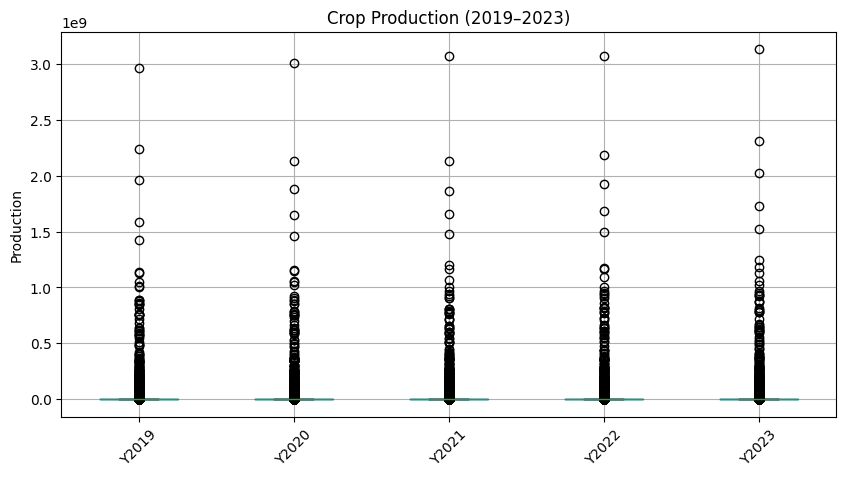

In [31]:
#Outliers
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

crop_production[["Y2019", "Y2020", "Y2021", "Y2022", "Y2023"]].boxplot()

plt.title("Crop Production (2019–2023)")
plt.ylabel("Production")
plt.xticks(rotation=45)
plt.show()

In [32]:
crop_production[["Y2019", "Y2020", "Y2021", "Y2022", "Y2023"]].describe()

,Y2019,Y2020,Y2021,Y2022,Y2023
count,2.732200e+04,2.735900e+04,2.747100e+04,2.749800e+04,2.253700e+04
mean,4.000586e+06,4.025384e+06,4.077036e+06,4.114633e+06,4.925600e+06
std,4.294733e+07,4.305710e+07,4.344791e+07,4.393339e+07,5.004746e+07
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.952345e+03,1.919865e+03,1.890460e+03,1.926420e+03,1.860000e+03
50%,2.917500e+04,2.861491e+04,2.838975e+04,2.846203e+04,3.005700e+04
75%,3.220953e+05,3.192874e+05,3.261622e+05,3.246570e+05,3.701560e+05
max,2.964207e+09,3.008965e+09,3.070651e+09,3.073689e+09,3.134294e+09


In [33]:
%who

MinMaxScaler	 col	 crop_clean	 crop_df	 crop_production	 file	 files	 np	 os	 
pd	 plt	 uploaded	 weather_df	 weather_file	 zip_ref	 zipfile	 


## Week 2: Advanced EDA, Feature Engineering & Multivariate Analysis

In [34]:
# Calculate Percentage Growth from 2019 to 2023
crop_production['YoY_Growth_Pct'] = (
    (crop_production['Y2023'] - crop_production['Y2019']) / crop_production['Y2019']
) * 100

# Display top growing crops (excluding NaN or infinite values)
print("Top Growing Crops (2019-2023):")
display(
    crop_production[['Item', 'Y2019', 'Y2023', 'YoY_Growth_Pct']]
    .dropna()
    .sort_values(by='YoY_Growth_Pct', ascending=False)
    .head(10)
)

Top Growing Crops (2019-2023):


,Item,Y2019,Y2023,YoY_Growth_Pct
72901,Eggplants (aubergines),0.0,20.0,inf
72934,"Hazelnuts, in shell",0.0,200.0,inf
18506,Grapes,0.0,10.0,inf
35627,"Peas, green",0.0,2.0,inf
73171,"Walnuts, in shell",0.0,160.0,inf
73050,Other stone fruits,0.0,10.0,inf
55214,"Ginger, raw",0.0,11.0,inf
33079,"Meat of goat, fresh or chilled",0.0,10.0,inf
43435,Eggplants (aubergines),0.0,1400.0,inf
43771,Artichokes,0.0,10.0,inf


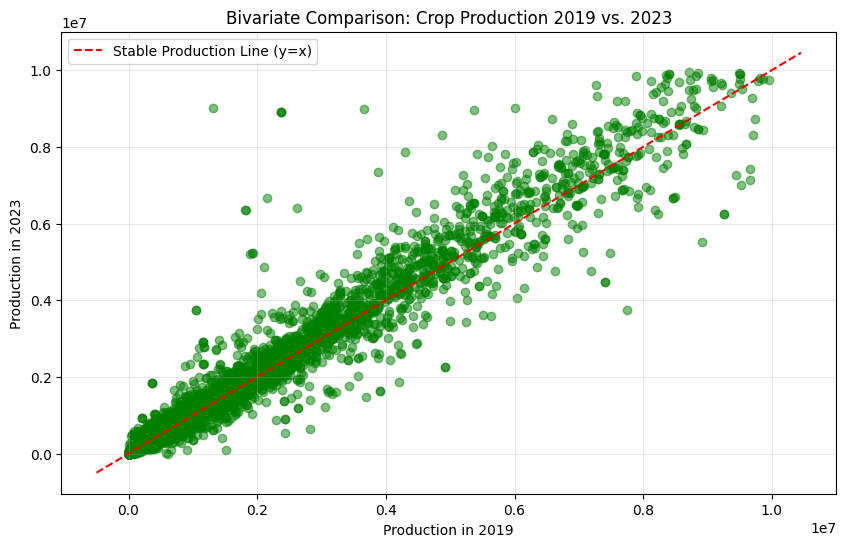

In [35]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 6))
x = crop_production['Y2019']
y = crop_production['Y2023']

# Filter out extreme outliers for a cleaner scatter plot visualization
filtered_data = crop_production[(crop_production['Y2019'] < 1e7) & (crop_production['Y2023'] < 1e7)].dropna(subset=['Y2019', 'Y2023'])

plt.scatter(filtered_data['Y2019'], filtered_data['Y2023'], alpha=0.5, color='green')

# Add a 45-degree reference line (y = x)
lims = [
    min(plt.xlim()[0], plt.ylim()[0]),
    max(plt.xlim()[1], plt.ylim()[1]),
]
plt.plot(lims, lims, color='red', linestyle='--', label='Stable Production Line (y=x)')

plt.title('Bivariate Comparison: Crop Production 2019 vs. 2023')
plt.xlabel('Production in 2019')
plt.ylabel('Production in 2023')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

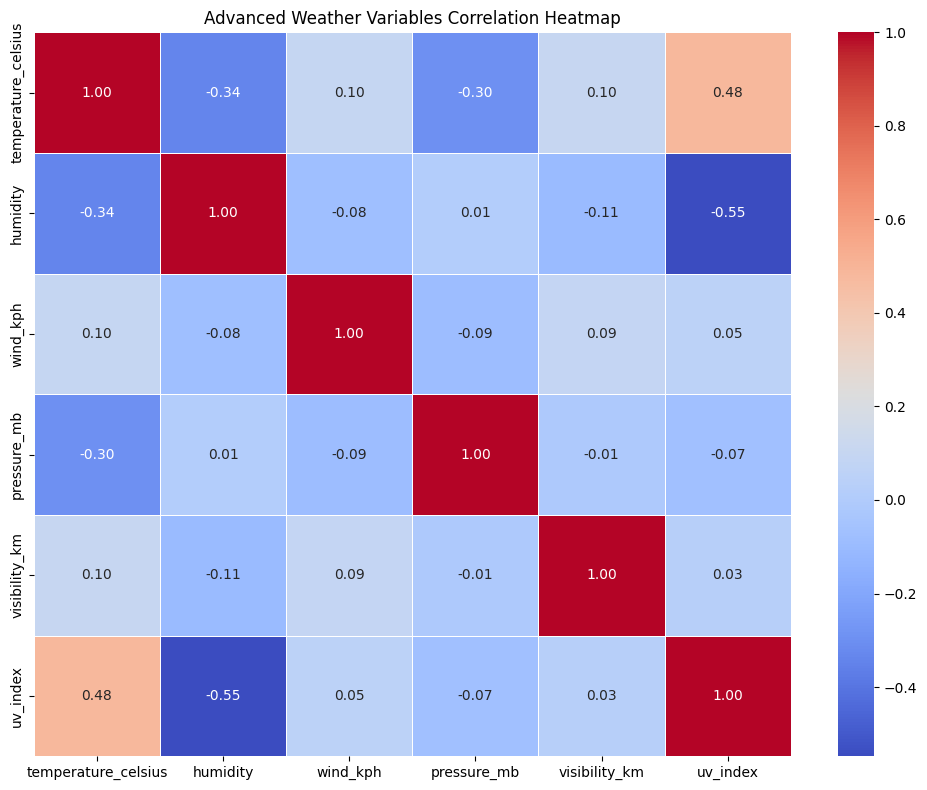

In [36]:
import seaborn as sns

plt.figure(figsize=(10, 8))
weather_subset = weather_df[[
    'temperature_celsius', 'humidity', 'wind_kph',
    'pressure_mb', 'visibility_km', 'uv_index'
]].dropna()

sns.heatmap(weather_subset.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Advanced Weather Variables Correlation Heatmap')
plt.tight_layout()
plt.show()

## Week 3: Predictive Modeling & Forecasting (Linear Regression)


--- Model Performance Metrics ---
R-squared (R2) Score: 0.9992435426130598
Root Mean Squared Error (RMSE): 1346672.4783983664


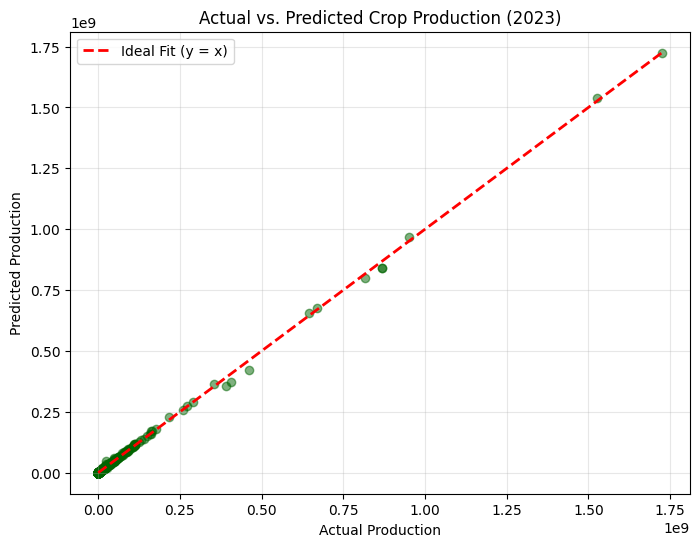

In [37]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import numpy as np

# Prepare features (X) and target (y) using historical production years
model_df = crop_production[['Y2019', 'Y2020', 'Y2021', 'Y2022', 'Y2023']].dropna()

X = model_df[['Y2019', 'Y2020', 'Y2021', 'Y2022']]
y = model_df['Y2023']

# Split data into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train the Linear Regression model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Generate predictions on the test set
y_pred = lr_model.predict(X_test)

# Evaluate model performance
print("--- Model Performance Metrics ---")
print("R-squared (R2) Score:", r2_score(y_test, y_pred))
print("Root Mean Squared Error (RMSE):", np.sqrt(mean_squared_error(y_test, y_pred)))

# Visualization: Actual vs Predicted Crop Production
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5, color='darkgreen')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Fit (y = x)')
plt.title('Actual vs. Predicted Crop Production (2023)')
plt.xlabel('Actual Production')
plt.ylabel('Predicted Production')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()